## Bluesky API Analysis: The Relationship Between Follower Count and Post Engagement

### Hypothesis: Bluesky accounts with higher follower counts will receive more average engagement (likes, replies, and reposts) on their posts than accounts with fewer followers.

Theoretical application: Social media engagement may be influenced by the size of an account's audience. Accounts with more followers potentially have greater visibility, which could increase the number of interactions their posts receive.

Statistical application: This hypothesis can be investigated by comparing follower counts with average engagement per post. A scatterplot and correlation coefficient can help identify whether accounts with larger audiences tend to receive more engagement.

Variables:
- Independent variable: Follower count
- Dependent variable: Average engagement per post (likes + replies + reposts)
- Additional variables: Account handle, post URI, individual engagement counts, and post creation date

endpoints needed: app.bsky.actor.getProfile, app.bsky.feed.getAuthorFeed

reliability and limitations: Bluesky search does not return all posts. Engagement counts change over time. Deleted posts will not appear. Some accounts may be inactive or private. API may limit how many posts are returned.

In [3]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [13]:
accounts = [
    "bsky.app",
    "jay.bsky.social",
    "npr.org",
    "theonion.com",
    "wired.com"
]

base_url = "https://public.api.bsky.app/xrpc/"

In [5]:
profile_list = []

for account in accounts:
    url = base_url + "app.bsky.actor.getProfile"

    response = requests.get(
        url,
        params={"actor": account},
        timeout=20
    )

    if response.status_code == 200:
        data = response.json()

        profile_list.append({
            "handle": data["handle"],
            "followers": data.get("followersCount", 0),
            "following": data.get("followsCount", 0),
            "postsCount": data.get("postsCount", 0)
        })

    else:
        print("Request failed for:", account,
              response.status_code)

profile_df = pd.DataFrame(profile_list)

profile_df.head()

,handle,followers,following,postsCount
0,bsky.app,35312355,22,883
1,jay.bsky.social,204,0,0
2,npr.org,1012854,238,19279
3,theonion.com,1358885,5,8818
4,wired.com,482956,82,11880


My data comes from the public Bluesky API. I used app.bsky.actor.getProfile to collect profile information, including follower counts, and app.bsky.feed.getAuthorFeed to collect posts and engagement counts. The API returns JSON objects, which I converted into pandas DataFrames

In [6]:
post_list = []

for account in profile_df["handle"]:
    url = base_url + "app.bsky.feed.getAuthorFeed"

    response = requests.get(
        url,
        params={
            "actor": account,
            "limit": 100,
            "filter": "posts_no_replies"
        },
        timeout=20
    )

    if response.status_code == 200:
        data = response.json()

        for item in data.get("feed", []):
            post = item["post"]

            # Keep only posts authored by this account
            if post["author"]["handle"] != account:
                continue

            # Exclude reposted feed items
            if item.get("reason", {}).get("$type") == \
                    "app.bsky.feed.defs#reasonRepost":
                continue

            post_list.append({
                "handle": account,
                "post_uri": post["uri"],
                "likes": post.get("likeCount", 0),
                "replies": post.get("replyCount", 0),
                "reposts": post.get("repostCount", 0),
                "created_at": post.get(
                    "record", {}
                ).get("createdAt")
            })

    else:
        print("Feed request failed for:", account,
              response.status_code)

posts_df = pd.DataFrame(post_list)

posts_df.head()

,handle,post_uri,likes,replies,reposts,created_at
0,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,340,23,50,2026-10-19T20:53:01.192Z
1,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,8910,630,1730,2026-10-17T21:55:13.889Z
2,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,1035,111,116,2026-10-16T20:09:31.738Z
3,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,1410,176,201,2026-10-16T16:23:26.498Z
4,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2843,69,351,2026-10-14T21:06:12.577Z


In [7]:
posts_df["total_engagement"] = (
    posts_df["likes"] +
    posts_df["replies"] +
    posts_df["reposts"]
)

posts_df.head()

,handle,post_uri,likes,replies,reposts,created_at,total_engagement
0,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,340,23,50,2026-10-19T20:53:01.192Z,413
1,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,8910,630,1730,2026-10-17T21:55:13.889Z,11270
2,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,1035,111,116,2026-10-16T20:09:31.738Z,1262
3,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,1410,176,201,2026-10-16T16:23:26.498Z,1787
4,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2843,69,351,2026-10-14T21:06:12.577Z,3263


In [8]:
combined_df = pd.merge(
    posts_df,
    profile_df,
    on="handle",
    how="inner"
)

combined_df.head()

,handle,post_uri,likes,replies,reposts,created_at,total_engagement,followers,following,postsCount
0,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,340,23,50,2026-10-19T20:53:01.192Z,413,35312355,22,883
1,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,8910,630,1730,2026-10-17T21:55:13.889Z,11270,35312355,22,883
2,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,1035,111,116,2026-10-16T20:09:31.738Z,1262,35312355,22,883
3,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,1410,176,201,2026-10-16T16:23:26.498Z,1787,35312355,22,883
4,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2843,69,351,2026-10-14T21:06:12.577Z,3263,35312355,22,883


In [9]:
average_df = combined_df.groupby(
    "handle", as_index=False
).agg(
    followers=("followers", "first"),
    average_engagement=("total_engagement", "mean"),
    number_of_posts=("post_uri", "nunique")
)

average_df = average_df.sort_values(
    "followers", ascending=False
)

average_df

,handle,followers,average_engagement,number_of_posts
0,bsky.app,35312355,5657.757576,66
2,theonion.com,1358885,1355.382979,94
1,npr.org,1012854,224.960000,100
3,wired.com,482956,135.661538,65


I created separate DataFrames for account information and post engagement. I calculated total engagement by adding likes, replies, and reposts. I then used pd.merge() to combine the DataFrames using the account handle as a shared variable. Finally, I used groupby() to calculate average engagement per account.

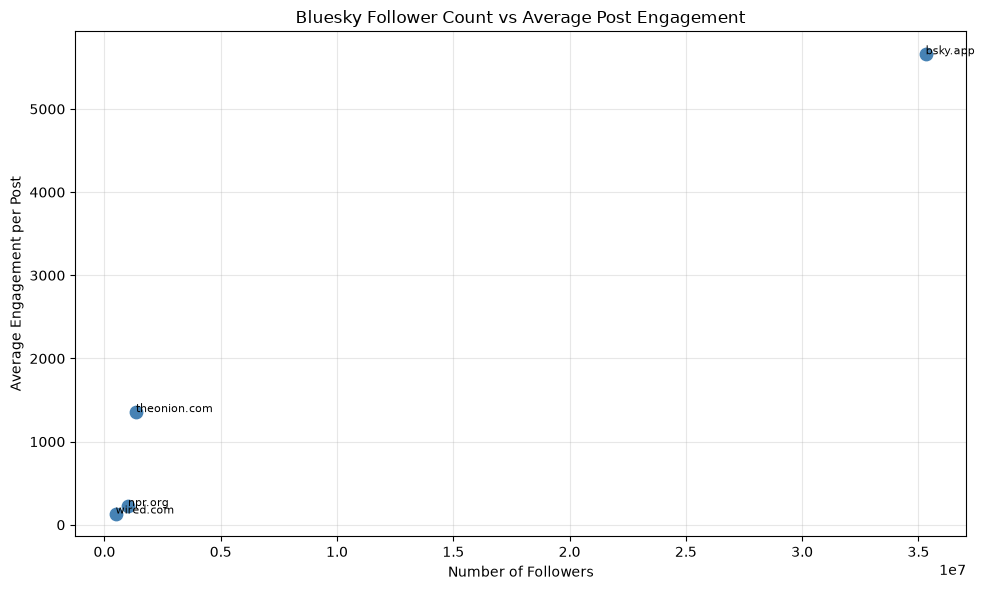

In [10]:
plt.figure(figsize=(10, 6))

plt.scatter(
    average_df["followers"],
    average_df["average_engagement"],
    color="steelblue",
    s=80
)

for _, row in average_df.iterrows():
    plt.annotate(
        row["handle"],
        (row["followers"], row["average_engagement"]),
        fontsize=8
    )

plt.xlabel("Number of Followers")
plt.ylabel("Average Engagement per Post")
plt.title("Bluesky Follower Count vs Average Post Engagement")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

I created a scatterplot comparing the number of followers an account has with its average post engagement. Each point represents one account. This allows me to examine whether accounts with more followers tend to receive more engagement.

In [11]:
correlation = average_df[
    "followers"
].corr(average_df["average_engagement"])

print("Correlation:", round(correlation, 3))

Correlation: 0.981


## Conclusion: This project investigated the relationship between Bluesky follower counts and average post engagement. The data showed a positive relationship, suggesting that accounts with more followers tended to receive more engagement. The correlation coefficient was .981. These findings are exploratory because the analysis included a small selection of accounts and a limited number of posts. Future research could examine more accounts, collect posts over a longer period, and consider other factors such as posting frequency and content type.